# Tuberculosis Chest X-ray: CNN + LIME

Tuberculosis still kills more than a million people a year, and in many clinics the first test is a chest X-ray read by whoever is on duty. This notebook teaches a CNN to flag TB on 4,200 X-rays, then asks the question most TB notebooks skip: **is the model looking at the lungs, or at the hospital the X-ray came from?**

**Data** → [Tuberculosis (TB) Chest X-ray Database](https://www.kaggle.com/datasets/tawsifurrahman/tuberculosis-tb-chest-xray-dataset) · 3,500 normal + 700 TB images · 512×512 PNG

**Objectives**
1. Find shortcuts before the model does → image sources, file properties, near-duplicates
2. Split honestly → near-duplicate X-rays never sit on both sides of the split
3. Prepare the images → contrast enhancement and a lung mask
4. Fine-tune EfficientNetB0 → threshold chosen for screening (sensitivity first)
5. Check where it looks → hide the lungs, then explain single predictions with LIME

<!-- objective -->
## Objective

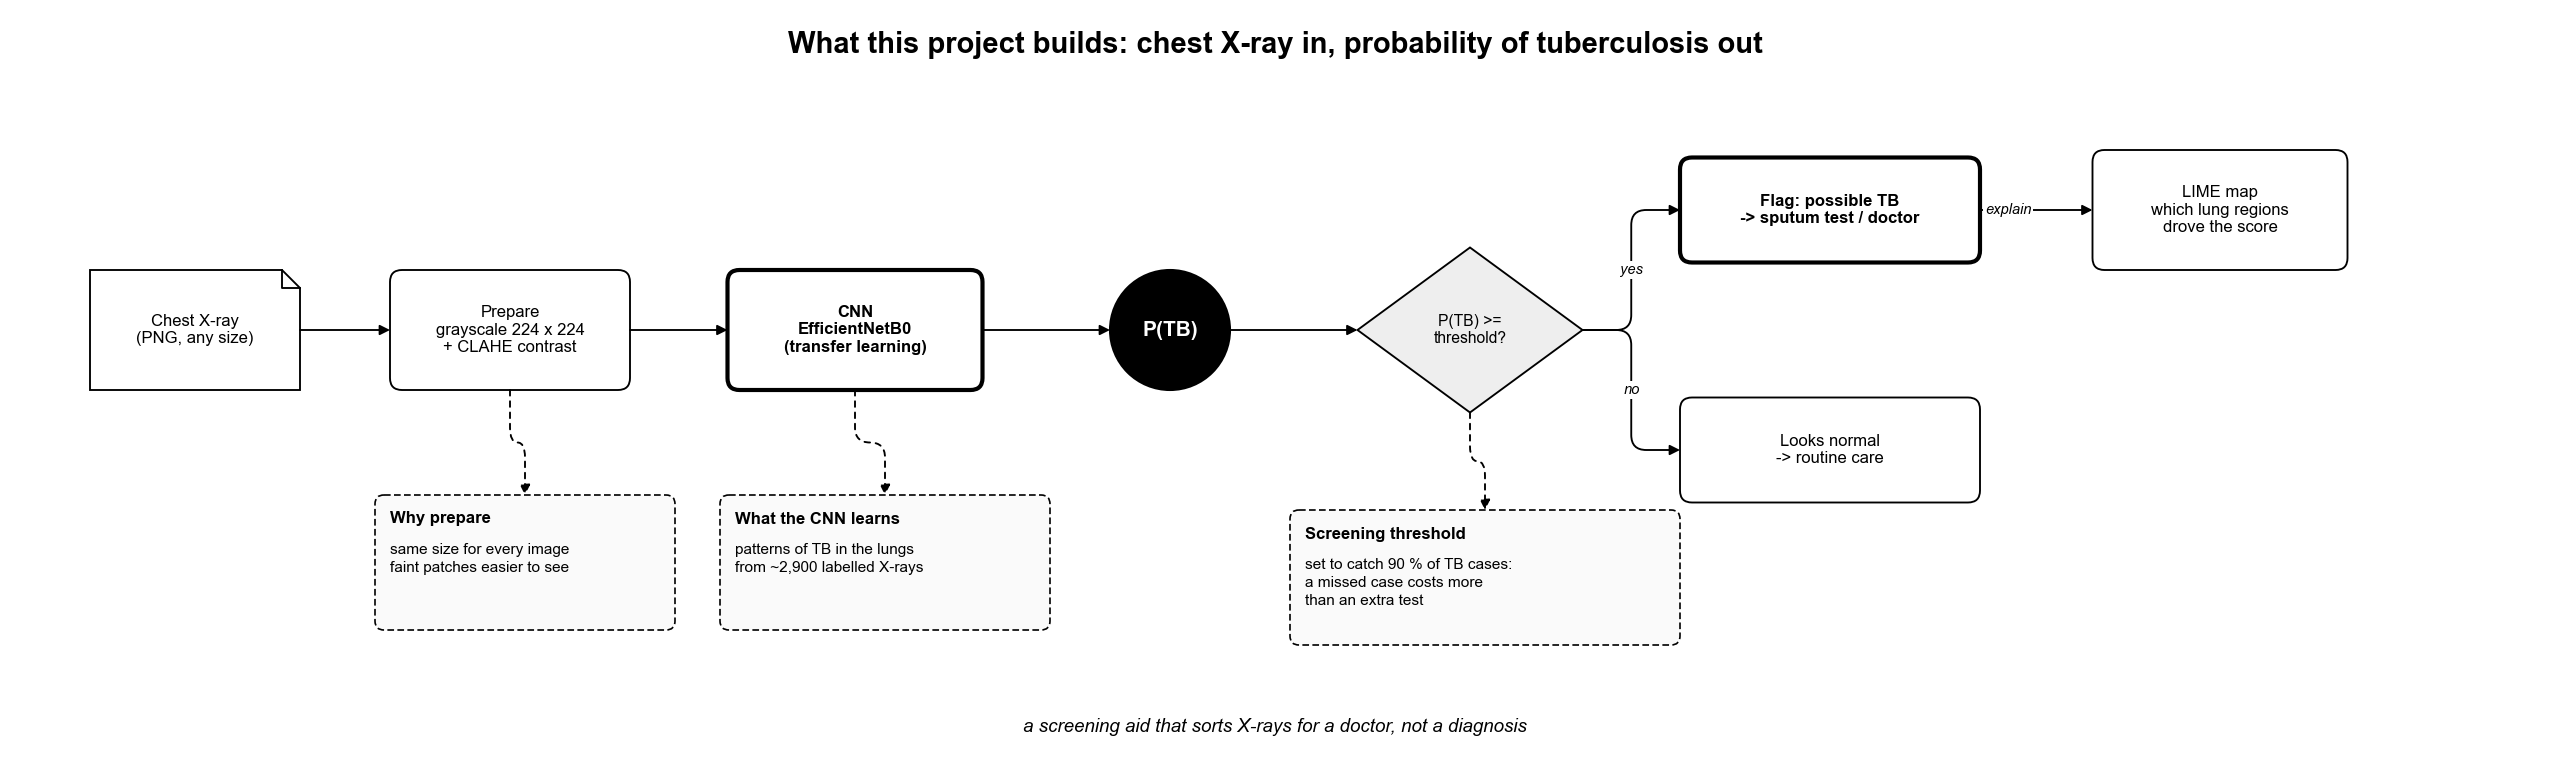

- **Problem** → tuberculosis still kills more than a million people a year; many clinics can take a chest X-ray but have no radiologist on duty, so X-rays wait
- **Why this repo** → train a CNN that gives every X-ray a probability of TB, set the threshold so it catches 90 % of TB cases, and test whether it looks at the lungs or at the hospital the X-ray came from
- **Real-world use** → a triage queue: likely-TB X-rays are read first and sent for a sputum test; the LIME map shows the doctor which regions drove the score

# [1/13] Setup

Settings, imports and one printing helper → everything that writes to disk is off by default

In [ ]:
"""Optional · Add Input → dataset tawsifurrahman/tuberculosis-tb-chest-xray-dataset, Accelerator GPU, Internet On, then Run All.

[1/16] DATA_DIR: dataset folder (searched recursively for Normal/ and Tuberculosis/)
    Default = '/kaggle/input/tuberculosis-tb-chest-xray-dataset'
[2/16] WORK_DIR: folder for the model file
    Default = '/kaggle/working'
[3/16] IMG_SIZE: image size in pixels
    Default = 224
    For example:
        IMG_SIZE = 160
[4/16] ENHANCE: contrast enhancement applied to every image
    Default = 'clahe'
    For example:
        ENHANCE = None
        ENHANCE = 'stretch'
        ENHANCE = 'equalize'
[5/16] HASH_SIZE: difference-hash grid for the near-duplicate search (HASH_SIZE² bits)
    Default = 16
[6/16] DUP_HAMMING: max differing bits for two images to count as near-duplicates
    Default = 10
    For example:
        DUP_HAMMING = 0
[7/16] N_JOBS: threads for reading PNGs
    Default = 4
[8/16] BATCH_SIZE: images per training step
    Default = 32
[9/16] EPOCHS_HEAD: max epochs while the backbone is frozen
    Default = 10
[10/16] EPOCHS_FINE_TUNE: max epochs while fine-tuning
    Default = 8
[11/16] FINE_TUNE_LAST_N: backbone layers unfrozen when fine-tuning
    Default = 20
[12/16] TARGET_SENSITIVITY: share of TB cases the threshold must catch on validation
    Default = 0.90
    For example:
        TARGET_SENSITIVITY = 0.95
[13/16] LIME_SAMPLES: perturbed images per LIME explanation
    Default = 300
    For example:
        LIME_SAMPLES = 1000
[14/16] SAVE_MODEL: save the trained model (+ settings.json for the app)
    Default = False
[15/16] LAUNCH_APP: start the Gradio screening app at the end (public link on Kaggle)
    Default = False
[16/16] DISPLAY_SEED: which images are shown in the example grids (None = a new random sample on every run)
    Default = None
    For example:
        DISPLAY_SEED = 7
"""
DATA_DIR           = '/kaggle/input/tuberculosis-tb-chest-xray-dataset'
WORK_DIR           = '/kaggle/working'
IMG_SIZE           = 224
ENHANCE            = 'clahe'
HASH_SIZE          = 16
DUP_HAMMING        = 10
N_JOBS             = 4
BATCH_SIZE         = 32
EPOCHS_HEAD        = 10
EPOCHS_FINE_TUNE   = 8
FINE_TUNE_LAST_N   = 20
TARGET_SENSITIVITY = 0.90
LIME_SAMPLES       = 300
SAVE_MODEL         = False
LAUNCH_APP         = False

DISPLAY_SEED       = None
SEED               = 42
MODEL_FILE         = f'{WORK_DIR}/tuberculosis_effnetb0.keras'
SETTINGS_FILE      = f'{WORK_DIR}/settings.json'
CLASSES            = ['Normal', 'Tuberculosis']
CLASS_NAMES        = {0: 'normal', 1: 'TB'}
PALETTE            = {0: 'black', 1: 'red'}
PAD                = 30

In [ ]:
%pip install -q lime
import gc
import json
import os
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from PIL import Image
from scipy import ndimage
from scipy.sparse.csgraph import connected_components
from skimage.measure import label, regionprops
from skimage.segmentation import clear_border, mark_boundaries
from tqdm.auto import tqdm

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from lime import lime_image
from lime.wrappers.scikit_image import SegmentationAlgorithm

from sklearn.metrics import (ConfusionMatrixDisplay, average_precision_score, classification_report,
                             confusion_matrix, precision_recall_curve, roc_auc_score, roc_curve)
from sklearn.model_selection import StratifiedGroupKFold

keras.utils.set_random_seed(SEED)
sns.set_theme(style='whitegrid')

In [ ]:
def show_block(title, items):
    print(f'{title}:')
    for key, value in items.items():
        print(f'    {key:<{PAD}}{value}')

show_rng = np.random.default_rng(DISPLAY_SEED)   # only decides which example images are displayed


# [2/13] Data

List every X-ray and read where it came from → 1 TB image for every 5 normal ones, collected from different sources

In [ ]:
def find_database(*roots):
    """First folder that contains both class sub-folders (Normal/ and Tuberculosis/), searched recursively."""
    for root in roots:
        root = Path(root)
        if not root.exists():
            continue
        for normal in sorted(root.rglob('Normal')):
            if normal.is_dir() and all((normal.parent / cls).is_dir() for cls in CLASSES):
                return normal.parent
    return None


# DATA_DIR first; if the dataset is mounted elsewhere (Kaggle paths differ between setups), search all of /kaggle/input
db_dir = find_database(DATA_DIR, '/kaggle/input')
if db_dir is None:
    mounted = sorted(str(p) for p in Path('/kaggle/input').glob('*/*')) if Path('/kaggle/input').exists() else []
    raise FileNotFoundError(
        f'(!) No folder with {CLASSES} sub-folders under {DATA_DIR} or /kaggle/input.\n'
        f'    Add Input -> Datasets -> tawsifurrahman/tuberculosis-tb-chest-xray-dataset\n'
        f'    Mounted now: {mounted[:20] or "nothing"}')

files_df = pd.DataFrame([{'file': p.name, 'path': str(p), 'class': cls, 'target': target}
                         for target, cls in enumerate(CLASSES)
                         for p in sorted((db_dir / cls).glob('*.png'))])
show_block('Outputs', {'database folder': db_dir, 'files_df': files_df.shape})

In [ ]:
display(files_df.head())

**Question:** How rare is TB in this dataset?

**Answer:** **700 of 4,200 X-rays (16.7%)**, 1 TB image for every 5 normal ones. Milder than most medical data, but a model that always says "normal" is still 83% accurate and catches no TB at all, like a smoke alarm with no battery → models are judged by sensitivity, specificity and ROC-AUC ([11/13]), not accuracy.

In [ ]:
counts = files_df['target'].value_counts().sort_index()
display(pd.DataFrame({'images': counts, 'share %': (counts / counts.sum() * 100).round(2)}).rename(index=CLASS_NAMES))

In [ ]:
fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(counts.index.map(CLASS_NAMES), counts.values, color=[PALETTE[0], PALETTE[1]])
for bar, n in zip(bars, counts.values):
    ax.annotate(f'{n:,}\n({n / counts.sum():.1%})', (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                ha='center', va='bottom')
ax.set_title('Images per class')
ax.set_ylabel('Images')
ax.margins(y=0.2)
plt.show()

**Question:** Where do the X-rays come from?

The dataset page lists four collections: the NLM sets (Montgomery, USA and Shenzhen, China), a Belarus TB study, the NIAID TB portal and the RSNA pneumonia challenge. The two metadata sheets give each image's source URL.

**Answer:** the class can be read from the source.
- Belarus TB study → 306 X-rays, **100 % TB**; Kaggle / RSNA → 3,094 X-rays, **100 % normal**
- only the NLM sets (Montgomery + Shenzhen, 800 X-rays) mix both classes (49 % TB)
- → a model can score well by recognising the hospital; [12/13] tests whether it does


In [ ]:
def read_metadata(cls):
    path = db_dir / f'{cls}.metadata.xlsx'
    if not path.exists():
        return pd.DataFrame()
    meta = pd.read_excel(path)
    meta.columns = [str(col).strip().lower() for col in meta.columns]
    return meta.assign(**{'class': cls})


meta_df = pd.concat([read_metadata(cls) for cls in CLASSES], ignore_index=True)
url_col = next((col for col in meta_df.columns if 'url' in col), None)
show_block('Outputs', {'meta_df': meta_df.shape, 'url column': url_col})

In [ ]:
if url_col:
    meta_df['source'] = meta_df[url_col].astype(str).str.extract(r'https?://(?:www\.)?([^/]+)')[0].fillna('unknown')
    sources = pd.crosstab(meta_df['source'], meta_df['class'])
    sources['TB %'] = (sources['Tuberculosis'] / sources.sum(axis=1) * 100).round(1)
    display(sources.sort_values('Tuberculosis', ascending=False))
else:
    print('(!) no URL column in the metadata sheets → source check skipped')

# [3/13] File properties

Read only the PNG headers and compare the classes → any property that differs by class is a free shortcut for the CNN

**Question:** Do normal and TB files differ before anyone looks at a lung?

A CNN is lazy in the best and worst way: it uses whatever separates the classes. If TB images were saved in a different colour mode or with a different compression, the model can score well by recognising the **file**, like a teacher who grades exams by the colour of the paper.

**Answer:** yes.
- all 308 grayscale (`L`) files are TB; every normal file is RGB
- TB files are smaller and far more varied (median 142 kB, std 67) than normal ones (169 kB, std 14) → different scanners and compression
- grayscale loading removes the mode difference, not the compression fingerprint


In [ ]:
def file_props(path):
    with Image.open(path) as image:
        return {'mode': image.mode, 'size': f'{image.size[0]}x{image.size[1]}', 'kB': os.path.getsize(path) / 1024}


with ThreadPoolExecutor(max_workers=N_JOBS) as pool:
    props_df = pd.DataFrame(list(tqdm(pool.map(file_props, files_df['path']), total=len(files_df),
                                      desc='[1.1] Reading PNG headers')))
props_df['class'] = files_df['target'].map(CLASS_NAMES)
show_block('Outputs', {'props_df': props_df.shape})

In [ ]:
for col in ['mode', 'size']:
    table = pd.crosstab(props_df[col], props_df['class'])
    table['TB %'] = (table['TB'] / table.sum(axis=1) * 100).round(1)
    display(table)
display(props_df.groupby('class')['kB'].describe().round(1))

In [ ]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.kdeplot(data=props_df, x='kB', hue='class', common_norm=False, fill=True, ax=ax,
            palette={'normal': PALETTE[0], 'TB': PALETTE[1]})
ax.set(title='PNG file size per class', xlabel='File size (kB)')
plt.show()

# [4/13] Load images

Read every PNG as one grayscale channel at `IMG_SIZE` → about 200 MB in memory at 224 px

**Question:** How do we turn 4,200 PNGs of 512×512 into model input?

**Answer:** Each file is read as a **grayscale** array of shape `(IMG_SIZE, IMG_SIZE)`, values 0 (black) to 255 (white). An X-ray has no colour, so three identical channels would only triple the memory; the copy to 3 channels happens later, batch by batch, because the pre-trained CNN expects RGB.
- `cv2.IMREAD_GRAYSCALE` → RGB and grayscale files end up identical
- `INTER_AREA` → shrinks by averaging blocks of pixels, like squinting at the picture: fine noise fades, shapes stay

In [ ]:
def load_gray(path, size=IMG_SIZE):
    image = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    return cv2.resize(image, (size, size), interpolation=cv2.INTER_AREA)


show_block('Inputs', {'images': f'{len(files_df):,}', 'size': f'{IMG_SIZE}x{IMG_SIZE}', 'threads': N_JOBS})

In [ ]:
with ThreadPoolExecutor(max_workers=N_JOBS) as pool:
    X_raw = np.stack(list(tqdm(pool.map(load_gray, files_df['path']), total=len(files_df), desc='[1.1] Loading PNGs')))
y_all = files_df['target'].to_numpy()
show_block('Outputs', {'X_raw': X_raw.shape, 'y_all': y_all.shape, 'memory': f'{X_raw.nbytes / 1024**2:.0f} MB'})

# [5/13] Near-duplicates and split

Fingerprint every X-ray, group look-alikes, then split by group → no near-copy of a test image is ever seen in training

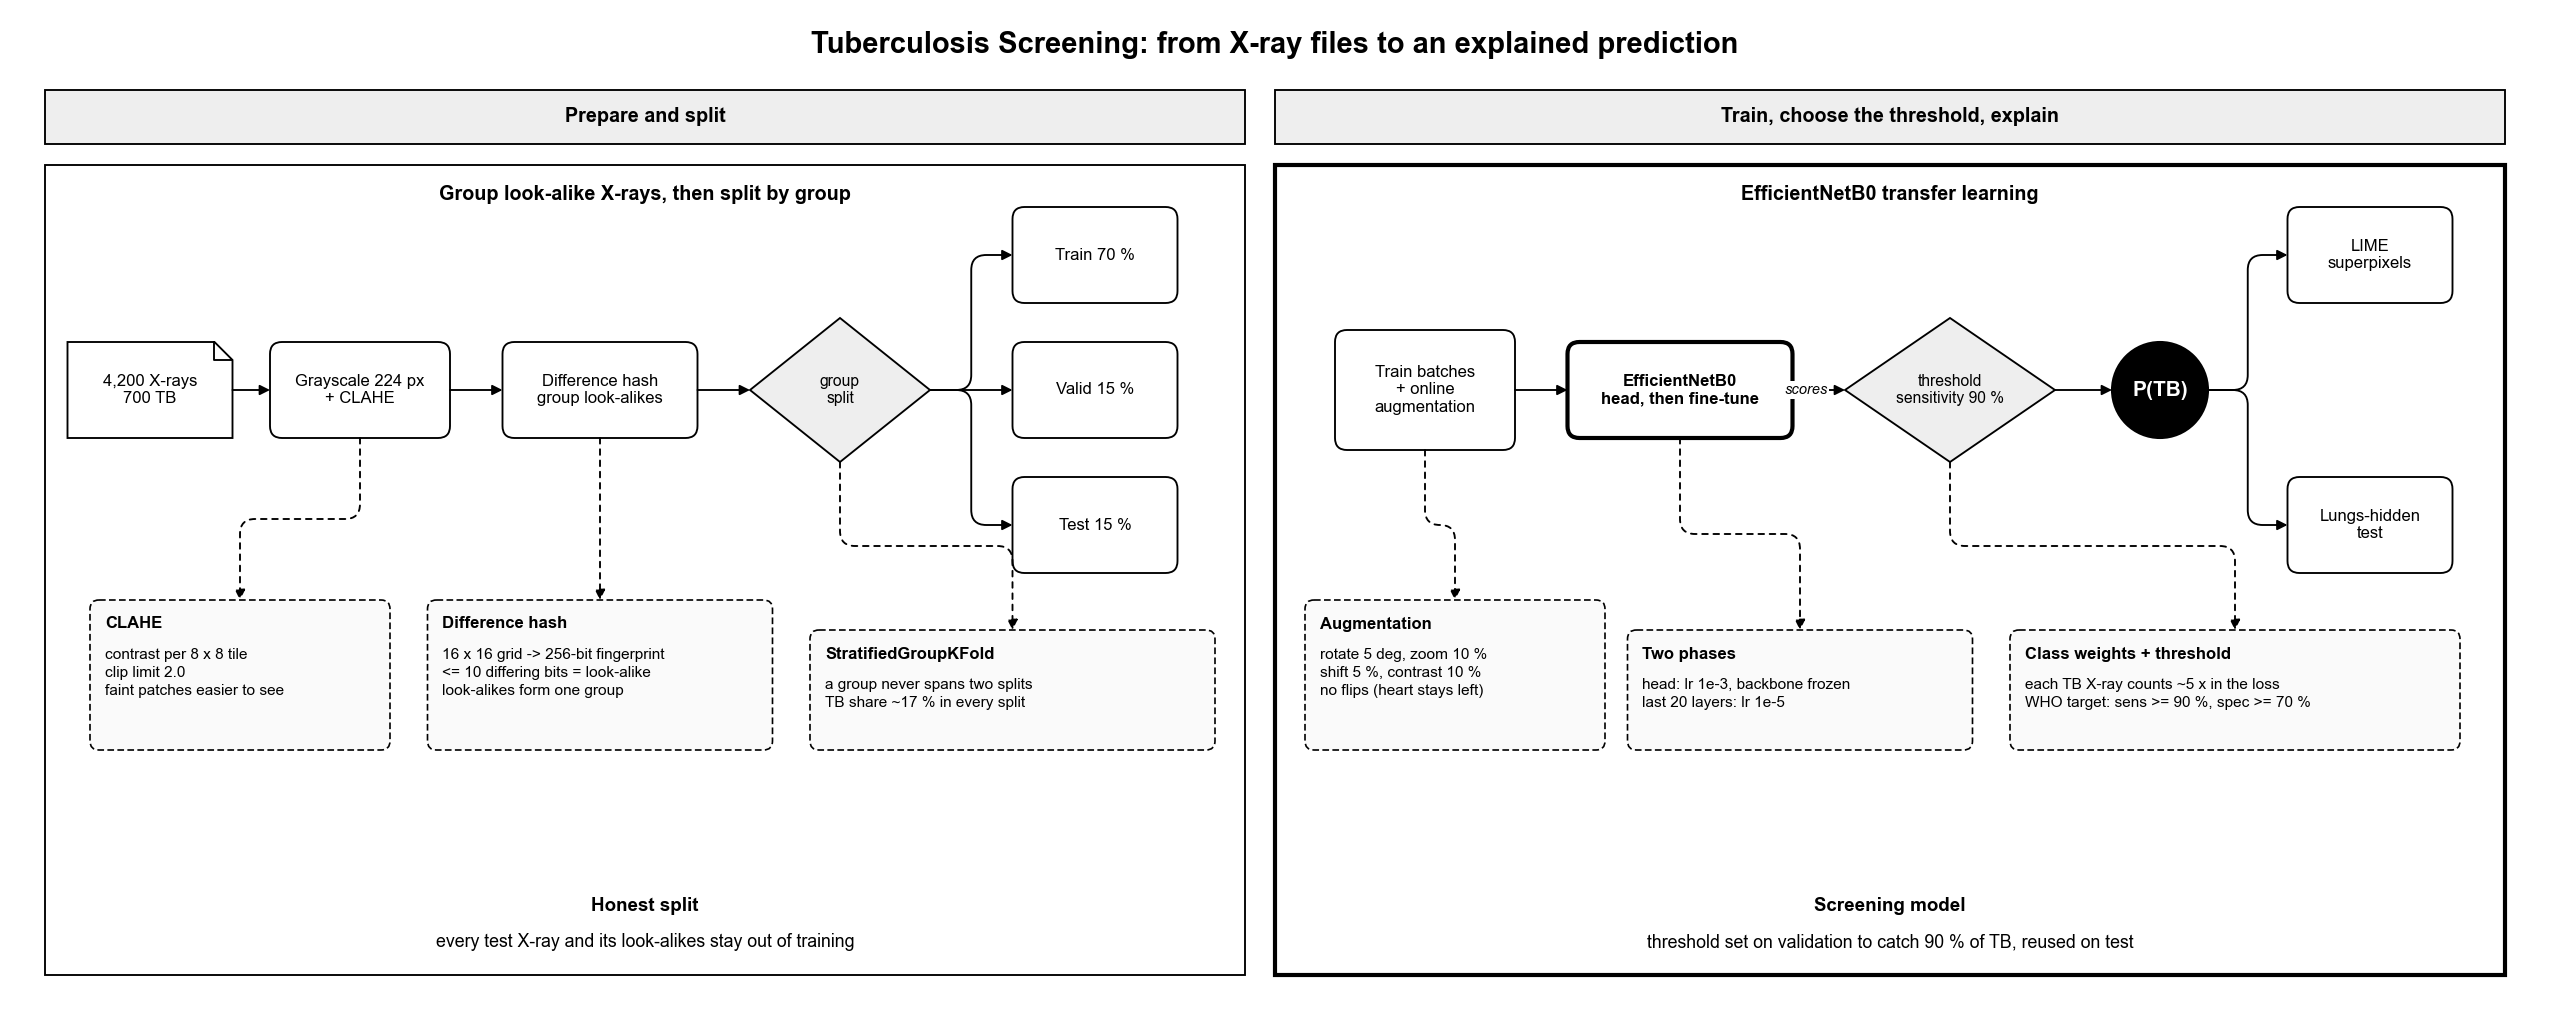


**Question:** Can the same X-ray hide twice in the data?

There are no patient IDs, and public X-ray collections are often re-shared, so the same image (or a re-scaled copy) can appear more than once. A copy in training and another in test turns the test into a memory quiz.

**1. Difference hash (dHash)** → shrink the image to $(H+1) \times H$ pixels and write down, for every pixel, whether it is brighter than its right-hand neighbour: $H^2$ bits, a fingerprint that survives resizing and small brightness changes.

**2. Hamming distance**

$$d(a, b) = \sum_{k=1}^{H^2} \mathbb{1}\left[a_k \neq b_k\right]$$
- $a, b$ → the bit fingerprints of two images
- $a_k \neq b_k$ → bit $k$ disagrees; $\mathbb{1}[\cdot]$ counts it as 1
- $d$ → number of disagreeing bits: 0 = same picture, ~half the bits = unrelated pictures
- Analogy → a spot-the-difference puzzle: count the differences between two pictures; 0-2 differences means it is the same photo

Images with $d \le$ `DUP_HAMMING` are linked, and linked images form one **group** (if A ≈ B and B ≈ C, all three are one group).

**Answer:** rarely: 20 X-rays have a look-alike (9 groups, largest 4) and no group mixes normal and TB. The median X-ray is 32 bits from its nearest neighbour, far above the threshold of 10 → grouping costs nothing and guarantees that no copy crosses the split.


In [ ]:
def dhash_bits(image, hash_size=HASH_SIZE):
    small = cv2.resize(image, (hash_size + 1, hash_size), interpolation=cv2.INTER_AREA).astype(np.int16)
    return (small[:, 1:] > small[:, :-1]).ravel()


bits     = np.stack([dhash_bits(x) for x in X_raw]).astype(np.float32)
distance = bits @ (1 - bits).T + (1 - bits) @ bits.T
np.fill_diagonal(distance, np.inf)
nearest  = distance.min(axis=1)
n_groups, group = connected_components(distance <= DUP_HAMMING, directed=False)
show_block('Outputs', {'fingerprint bits': bits.shape[1], 'groups': f'{n_groups:,} for {len(X_raw):,} images'})

In [ ]:
group_size  = np.bincount(group)[group]
group_label = pd.Series(y_all).groupby(group).agg(['min', 'max'])
display(pd.DataFrame({'value': {
    'images with a near-duplicate':   f'{(group_size > 1).sum():,}',
    'groups with 2+ images':          f'{(np.bincount(group) > 1).sum():,}',
    'largest group':                  f'{np.bincount(group).max()}',
    'groups mixing normal and TB':    f'{(group_label["min"] != group_label["max"]).sum()}',
    'median nearest distance (bits)': f'{np.median(nearest):.0f} of {bits.shape[1]}',
}}))
if np.bincount(group).max() > 50:
    print(f'(!) one group holds {np.bincount(group).max()} images → DUP_HAMMING is too loose for these X-rays')

In [ ]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(nearest, bins=np.arange(0, nearest.max() + 2) - 0.5, color='grey')
ax.axvline(DUP_HAMMING + 0.5, color='red', linestyle='--', label=f'DUP_HAMMING = {DUP_HAMMING}')
ax.set(title='Distance from each X-ray to its closest other X-ray', xlabel='Differing bits', ylabel='Images')
ax.legend()
plt.show()

In [ ]:
all_dup_groups = np.flatnonzero(np.bincount(group) > 1)
dup_groups = list(show_rng.choice(all_dup_groups, min(6, len(all_dup_groups)), replace=False)) if len(all_dup_groups) else []
if dup_groups:
    fig, axes = plt.subplots(len(dup_groups), 2, figsize=(7, 3.5 * len(dup_groups)), squeeze=False)
    for row, g in enumerate(dup_groups):
        i, j = np.flatnonzero(group == g)[:2]
        for ax, k in zip(axes[row], [i, j]):
            ax.imshow(X_raw[k], cmap='gray')
            ax.set_title(f"{files_df.loc[k, 'file']}  d = {distance[i, j]:.0f}", fontsize=9, color=PALETTE[y_all[k]])
            ax.axis('off')
    plt.suptitle('Near-duplicate pairs', fontweight='bold')
    plt.tight_layout()
    plt.show()
else:
    print('No near-duplicates at this threshold')

**Question:** How do we get honest validation and test sets?

**Answer:** `StratifiedGroupKFold` keeps every duplicate group in exactly one split and keeps the TB share similar across splits: ~1/7 of the groups → test, ~1/6 of the rest → validation → about **70 / 15 / 15**. An assertion stops the notebook if any group lands in two splits. 

In [ ]:
def grouped_split(groups, y, n_splits, seed=SEED):
    sgkf = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    return next(sgkf.split(np.zeros(len(y)), y, groups))


trainval_pos, test_idx = grouped_split(group, y_all, n_splits=7)
train_pos, val_pos     = grouped_split(group[trainval_pos], y_all[trainval_pos], n_splits=6)
train_idx, val_idx     = trainval_pos[train_pos], trainval_pos[val_pos]
splits                 = {'train': train_idx, 'val': val_idx, 'test': test_idx}

split_groups = {name: set(group[idx]) for name, idx in splits.items()}
shared       = (split_groups['train'] & split_groups['val']) | (split_groups['train'] & split_groups['test']) | (split_groups['val'] & split_groups['test'])
assert not shared, f'(!) {len(shared)} duplicate groups appear in more than one split'

display(pd.DataFrame({name: {'images': len(idx), 'TB': int(y_all[idx].sum()), 'TB %': round(y_all[idx].mean() * 100, 1)}
                      for name, idx in splits.items()}).T.astype({'images': int, 'TB': int}))

# [6/13] Image EDA

Look at the X-rays and average them per class → where normal and TB images differ, and whether the difference sits inside the lungs

**Question:** What do the X-rays look like?

**What to look for** → TB shows as hazy white patches (consolidation), small nodules or cavities, often in the **upper** lungs. Also look outside the lungs: text markers ("L", "R"), black borders, rotated or cropped images. Those are **acquisition** traits; if one class has more of them, the CNN may learn them instead of the disease.

In [ ]:
fig, axes = plt.subplots(4, 8, figsize=(17.6, 10))
for cls, rows in [(0, axes[:2]), (1, axes[2:])]:
    for ax, i in zip(rows.ravel(), show_rng.choice(np.flatnonzero(y_all == cls), rows.size, replace=False)):
        ax.imshow(X_raw[i], cmap='gray')
        ax.set_title(f"{CLASS_NAMES[cls]}\n{files_df.loc[i, 'file']}", fontsize=8, color=PALETTE[cls])
        ax.axis('off')
plt.suptitle('Random normal (top two rows) and TB (bottom two rows) X-rays', fontweight='bold')
plt.tight_layout()
plt.show()

**Question:** What does the *average* normal and TB X-ray look like?

$$\bar I_c(x, y) = \frac{1}{n_c} \sum_{i \in c} I_i(x, y)$$
- $\bar I_c(x, y)$ → **mean image** of class $c$: the average brightness at pixel $(x, y)$
- $I_i(x, y)$ → brightness of X-ray $i$ at that pixel
- $n_c$ → number of X-rays in class $c$
- Analogy → stacking hundreds of transparent slides of the same street: parked cars blur away, buildings stay sharp

The difference map $\bar I_{TB} - \bar I_{normal}$ shows **where** the classes differ on average: red = brighter in TB, blue = darker.

**Answer:** both kinds of difference are there.
- inside the lungs the TB mean is brighter (red) → denser tissue, the disease signal
- the strongest differences sit at the top corners and borders (up to +60 grey levels) → how each source took its X-rays, a shortcut the CNN can use


In [ ]:
mean_img = {cls: X_raw[y_all == cls].mean(axis=0) for cls in [0, 1]}
diff     = mean_img[1] - mean_img[0]
limit    = np.abs(diff).max()

fig, axes = plt.subplots(1, 3, figsize=(16, 5.2))
for ax, cls in zip(axes[:2], [0, 1]):
    ax.imshow(mean_img[cls], cmap='gray')
    ax.set_title(f'Mean {CLASS_NAMES[cls]} X-ray (n = {(y_all == cls).sum():,})')
im = axes[2].imshow(diff, cmap='coolwarm', vmin=-limit, vmax=limit)
axes[2].set_title('Mean TB − mean normal')
fig.colorbar(im, ax=axes[2], fraction=0.046)
for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.show()

**Question:** Do the classes differ in overall brightness, contrast or black borders?
- **Brightness** → mean pixel value of one X-ray
- **Contrast (std)** → how far pixel values spread from that mean
- **Black frame %** → share of near-black pixels (< 10) in the outer 8% frame: scanned films and some machines leave black borders

**Answer:** brightness is the same (median 125 vs 126), but normal X-rays have more contrast (64 vs 53) and twice the black frame (17 % vs 8 %) → one more acquisition fingerprint.


In [ ]:
def frame_black_share(image, frame=0.08, level=10):
    k      = max(1, int(image.shape[0] * frame))
    border = np.concatenate([image[:k].ravel(), image[-k:].ravel(), image[:, :k].ravel(), image[:, -k:].ravel()])
    return (border < level).mean() * 100


stats_df = pd.DataFrame({
    'brightness':     X_raw.reshape(len(X_raw), -1).mean(axis=1),
    'contrast (std)': X_raw.reshape(len(X_raw), -1).std(axis=1),
    'black frame %':  [frame_black_share(x) for x in X_raw],
    'class':          pd.Series(y_all).map(CLASS_NAMES),
})
display(stats_df.groupby('class').median().round(1))

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for ax, col in zip(axes, ['brightness', 'contrast (std)', 'black frame %']):
    sns.kdeplot(data=stats_df, x=col, hue='class', common_norm=False, fill=True, ax=ax,
                palette={'normal': PALETTE[0], 'TB': PALETTE[1]}, warn_singular=False)
    ax.set_title(col)
plt.tight_layout()
plt.show()

# [7/13] Contrast enhancement

Compare three ways to spread an X-ray's grey levels → `ENHANCE` picks one for every image

**Question:** Many X-rays look washed out. Can we make faint patches easier to see?

**1. Contrast stretching**

$$I'(x, y) = 255 \cdot \frac{I(x, y) - p_{2}}{p_{98} - p_{2}}$$
- $I(x, y)$ → original brightness of a pixel, $I'$ → new brightness, clipped to 0-255
- $p_2, p_{98}$ → the image's 2nd and 98th percentile: its "darkest" and "brightest" ignoring a few extreme pixels
- Analogy → a quiet recording turned up so its softest and loudest parts use the whole volume range

**2. Histogram equalization**

$$I'(x, y) = \operatorname{round}\big(255 \cdot \text{CDF}(I(x, y))\big)$$
- $\text{CDF}(v)$ → share of the image's pixels that are at most $v$
- each grey level moves to its rank: a pixel brighter than 70% of the image becomes $0.7 \times 255$
- Analogy → a crowded theatre re-seated so people spread evenly over all rows instead of packing the middle

**3. CLAHE** (Contrast Limited Adaptive Histogram Equalization)
- the same re-seating, but separately in an 8×8 grid of tiles, blended at the edges
- **clip limit** → no grey level may hold more than its share; the excess is spread out, so flat areas don't turn into amplified noise
- Analogy → every neighbourhood re-seats its own theatre, with a cap on how many people one row can take

Each method works on one image at a time and learns nothing from other images → it can run before the split without leaking.

**Answer:** All three spread the grey levels. Stretching only rescales, equalization can blow out the background, and CLAHE works locally, so ribs and lung texture stay visible → `ENHANCE = 'clahe'` by default. The earlier version of this project measured plain histogram equalization as the best of the three with its small CNN; set `ENHANCE = 'equalize'` to compare.

In [ ]:
def stretch(image, low=2, high=98):
    p_low, p_high = np.percentile(image, (low, high))
    return np.clip((image.astype(np.float32) - p_low) * 255.0 / max(p_high - p_low, 1), 0, 255).astype(np.uint8)


def equalize(image):
    return cv2.equalizeHist(image)


def clahe(image, clip=2.0, tiles=8):
    return cv2.createCLAHE(clipLimit=clip, tileGridSize=(tiles, tiles)).apply(image)


ENHANCERS = {None: lambda image: image, 'stretch': stretch, 'equalize': equalize, 'clahe': clahe}
assert ENHANCE in ENHANCERS, f'(!) ENHANCE must be one of {list(ENHANCERS)}'

In [ ]:
examples = [show_rng.choice(np.flatnonzero(y_all == 0)), *show_rng.choice(np.flatnonzero(y_all == 1), 2, replace=False)]
methods  = [('original', None), ('stretch', 'stretch'), ('equalize', 'equalize'), ('clahe', 'clahe')]

fig, axes = plt.subplots(2 * len(examples), 4, figsize=(16, 7.5 * len(examples)))
for row, i in enumerate(examples):
    for col, (name, key) in enumerate(methods):
        out = ENHANCERS[key](X_raw[i])
        axes[2 * row, col].imshow(out, cmap='gray', vmin=0, vmax=255)
        axes[2 * row, col].set_title(f'{CLASS_NAMES[y_all[i]]} · {name}', color=PALETTE[y_all[i]])
        axes[2 * row, col].axis('off')
        axes[2 * row + 1, col].hist(out.ravel(), bins=64, range=(0, 255), color='grey')
        axes[2 * row + 1, col].set_yticks([])
plt.suptitle('Contrast enhancement and the grey-level histogram it produces', fontweight='bold')
plt.tight_layout()
plt.show()

In [ ]:
X_all = np.stack([ENHANCERS[ENHANCE](x) for x in tqdm(X_raw, desc=f'[1.1] Enhancing ({ENHANCE})')])
show_block('Outputs', {'X_all': X_all.shape, 'enhancement': ENHANCE})

# [8/13] Lung mask

Segment the lungs with classic image processing → used later to test whether the CNN looks inside them

**Question:** Can we find the lungs without a trained segmentation model?

Roughly, yes: on an X-ray, air is dark and bone and tissue are bright, so the lungs are the two big dark regions inside the body.

1. **CLAHE** → evens out the contrast so both lungs come out equally dark
2. **Otsu threshold** → picks the grey level $t$ that splits pixels into "dark" and "bright" as cleanly as possible

    $$t^* = \underset{t}{\arg\max}\; \omega_0(t)\,\omega_1(t)\,\big[\mu_0(t) - \mu_1(t)\big]^2$$
    - $\omega_0, \omega_1$ → share of pixels darker / brighter than $t$
    - $\mu_0, \mu_1$ → average brightness of each side
    - Analogy → drawing the line between children and adults in a crowd by height so the two groups are as different as possible
3. **Clear border** → dark regions touching the image edge are air **outside** the body → removed
4. **Two largest regions** → left and right lung; smaller dark spots (stomach gas, noise) are dropped
5. **Closing, hole filling, dilation** → seal gaps left by ribs and vessels, then grow the mask slightly so the lung edges are inside it

**Answer:** well enough for a shortcut test: median lung area 24 % of the image for normal X-rays vs 18 % for TB (bright patches shrink the mask); 351 masks (8 %) fall outside 5-60 % and are rough.


In [ ]:
def odd_kernel(fraction, size):
    k = max(3, int(round(size * fraction)) | 1)
    return cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k, k))


def lung_mask_steps(image, keep=2):
    size       = image.shape[0]
    equalized  = clahe(image)
    blurred    = cv2.GaussianBlur(equalized, (5, 5), 0)
    _, dark    = cv2.threshold(blurred, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
    inside     = clear_border(dark > 0)
    labels     = label(inside)
    largest    = sorted(regionprops(labels), key=lambda r: r.area, reverse=True)[:keep]
    lungs      = np.isin(labels, [r.label for r in largest]).astype(np.uint8)
    closed     = cv2.morphologyEx(lungs, cv2.MORPH_CLOSE, odd_kernel(0.07, size))
    filled     = ndimage.binary_fill_holes(closed).astype(np.uint8)
    final      = cv2.dilate(filled, odd_kernel(0.03, size)).astype(bool)
    return {'1 CLAHE': equalized, '2 Otsu (dark = white)': dark, '3 clear border': inside,
            '4 two largest': lungs, '5 final mask': final}


def lung_mask(image):
    return lung_mask_steps(image)['5 final mask']

In [ ]:
shown = [*show_rng.choice(np.flatnonzero(y_all == 0), 2, replace=False), *show_rng.choice(np.flatnonzero(y_all == 1), 2, replace=False)]

fig, axes = plt.subplots(len(shown), 7, figsize=(24, 3.8 * len(shown)))
for row, i in enumerate(shown):
    steps = lung_mask_steps(X_raw[i])
    axes[row, 0].imshow(X_raw[i], cmap='gray')
    axes[row, 0].set_title(f'original · {CLASS_NAMES[y_all[i]]}', color=PALETTE[y_all[i]])
    for col, (name, img) in enumerate(steps.items(), start=1):
        axes[row, col].imshow(img, cmap='gray')
        axes[row, col].set_title(name)
    axes[row, 6].imshow(X_raw[i], cmap='gray')
    axes[row, 6].contour(steps['5 final mask'], colors='yellow', linewidths=1.5)
    axes[row, 6].set_title('overlay')
    for ax in axes[row]:
        ax.axis('off')
plt.suptitle('Lung mask, step by step', fontweight='bold')
plt.tight_layout()
plt.show()

In [ ]:
masks    = np.stack([lung_mask(x) for x in tqdm(X_raw, desc='[1.1] Lung masks')])
coverage = masks.reshape(len(masks), -1).mean(axis=1) * 100
failed   = (coverage < 5) | (coverage > 60)
display(pd.DataFrame({'median lung area %': pd.Series(coverage).groupby(y_all).median().round(1),
                      'masks outside 5-60 %': pd.Series(failed).groupby(y_all).sum()}).rename(index=CLASS_NAMES))

In [ ]:
del X_raw, bits, distance
gc.collect()
X_tr, y_tr   = X_all[train_idx], y_all[train_idx]
X_val, y_val = X_all[val_idx], y_all[val_idx]
X_te, y_te   = X_all[test_idx], y_all[test_idx]
show_block('Outputs', {
    'X_tr':  f'{X_tr.shape}  classes {np.bincount(y_tr)}',
    'X_val': f'{X_val.shape}  classes {np.bincount(y_val)}',
    'X_te':  f'{X_te.shape}  classes {np.bincount(y_te)}',
})

# [9/13] Imbalance and augmentation

Weight the rare class in the loss and vary the training images on the fly → no copies made before or after the split

**Question:** Training has about 5 normal X-rays per TB X-ray. How do we stop the CNN from ignoring TB?

**1. Class weights** → instead of copying TB images, each TB image counts more in the loss:

$$w_c = \frac{n}{2\,n_c}$$
- $w_c$ → weight of every image of class $c$ in the loss
- $n$ → all training images, $n_c$ → training images of class $c$
- $2$ → number of classes, so a balanced set gets $w = 1$ for both
- Analogy → a town meeting with 5 locals for every newcomer: each newcomer's vote counts 5× a local's, so both groups carry equal total say

**2. Online augmentation** → every epoch, every training image is shown slightly changed, inside the model, so no fixed copies exist that could leak into validation or test:

| Layer | Range | Why it is safe for X-rays |
|---|---|---|
| `RandomRotation` | ±5° | patients never stand perfectly straight |
| `RandomZoom` | ±10% | distance to the detector varies |
| `RandomTranslation` | ±5% | the chest is never exactly centred |
| `RandomContrast` | ±10% | exposure varies between machines |

**Not used: flips** → a mirrored X-ray puts the heart on the right, an anatomy almost no patient has. The model would learn from impossible pictures.

**Answer:** Training keeps its natural ratio, and each TB image weighs about 5× a normal one in the loss (exact weights below). Augmentation happens inside the model, after the split, so validation and test never contain a copy of a training image.

In [ ]:
counts       = np.bincount(y_tr)
class_weight = {cls: len(y_tr) / (2 * n) for cls, n in enumerate(counts)}
display(pd.DataFrame({'images': counts, 'weight': [round(w, 3) for w in class_weight.values()]}, index=['normal', 'TB']))

In [ ]:
augment = keras.Sequential([layers.RandomRotation(5 / 360),
                            layers.RandomZoom(0.1),
                            layers.RandomTranslation(0.05, 0.05),
                            layers.RandomContrast(0.1)], name='online_augmentation')

sample = X_tr[show_rng.choice(np.flatnonzero(y_tr == 1))].astype('float32')[None, :, :, None]
fig, axes = plt.subplots(1, 8, figsize=(24, 3.4))
axes[0].imshow(sample[0, :, :, 0], cmap='gray', vmin=0, vmax=255)
axes[0].set_title('original')
for ax in axes[1:]:
    ax.imshow(np.clip(augment(sample, training=True)[0, :, :, 0], 0, 255), cmap='gray', vmin=0, vmax=255)
    ax.set_title('augmented')
for ax in axes:
    ax.axis('off')
plt.suptitle('One random training X-ray, seven epochs of augmentation', fontweight='bold')
plt.tight_layout()
plt.show()

# [10/13] Modeling

Fine-tune a pre-trained EfficientNetB0 in two phases → the weights with the best validation AUC are kept

**Question:** Can a CNN pre-trained on everyday photos learn to read chest X-rays from ~2,900 images?

**1. Transfer learning** → EfficientNetB0 already learned edges, textures and shapes from 1.2M ImageNet photos. We keep that visual vocabulary and train a small new head on top, like hiring an experienced photographer and teaching them radiology instead of training someone who has never seen a picture.

**2. Sigmoid**

$$p = \sigma(z) = \frac{1}{1 + e^{-z}}$$
- $z$ → raw score from the network, any real number
- $p$ → predicted probability of TB, always between 0 and 1
- Analogy → a dimmer switch: however far you turn it, the light ends up between off and full

**3. Weighted binary cross-entropy**

$$L = -w_y\big[\,y \log p + (1 - y) \log (1 - p)\,\big]$$
- $y$ → true label: 1 TB, 0 normal
- $w_y$ → class weight from [9/13]
- $L$ → the error for one image, which training keeps shrinking
- Analogy → a weather forecaster: "99% sunny" on a rainy day costs far more than "60% sunny"; confident mistakes are punished hardest

**4. Training plan**
- **[1/2] Head** → backbone frozen, learning rate $10^{-3}$
- **[2/2] Fine-tune** → last `FINE_TUNE_LAST_N` backbone layers unfrozen, learning rate $10^{-5}$: 100× smaller, so it adjusts rather than overwrites what was learned
- **Grayscale → RGB** → the one channel is copied three times per batch, because the backbone expects colour input
- **Frozen BatchNorm** → the backbone keeps its ImageNet statistics, also while fine-tuning
- **Mixed precision** on GPU → float16 math, float32 output: faster, less memory

In [ ]:
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    keras.mixed_precision.set_global_policy('mixed_float16')
else:
    print('(!) No GPU found → training will be slow. Kaggle: Settings → Accelerator → GPU')
show_block('Outputs', {'TensorFlow': tf.__version__, 'GPUs': len(gpus),
                       'precision policy': keras.mixed_precision.global_policy().name})

In [ ]:
def to_rgb(image, label):
    return tf.image.grayscale_to_rgb(tf.cast(image, tf.float32)[..., None]), label


def make_dataset(X, y, training):
    ds = tf.data.Dataset.from_tensor_slices((X, y.astype('float32')))
    if training:
        ds = ds.shuffle(len(X), seed=SEED, reshuffle_each_iteration=True)
    return ds.map(to_rgb, num_parallel_calls=tf.data.AUTOTUNE).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)


train_ds = make_dataset(X_tr, y_tr, training=True)
val_ds   = make_dataset(X_val, y_val, training=False)
show_block('Outputs', {'train batches': len(train_ds), 'val batches': len(val_ds)})

In [ ]:
def build_model(img_size=IMG_SIZE, dropout=0.3):
    base = keras.applications.EfficientNetB0(include_top=False, weights='imagenet', input_shape=(img_size, img_size, 3))
    base.trainable = False

    inputs  = keras.Input(shape=(img_size, img_size, 3))
    x       = augment(inputs)
    x       = base(x, training=False)
    x       = layers.GlobalAveragePooling2D()(x)
    x       = layers.Dropout(dropout)(x)
    outputs = layers.Dense(1, activation='sigmoid', dtype='float32')(x)
    return keras.Model(inputs, outputs, name='tuberculosis_effnetb0'), base


def make_metrics():
    return [keras.metrics.AUC(name='auc'), keras.metrics.Precision(name='precision'), keras.metrics.Recall(name='recall')]


def make_callbacks():
    return [keras.callbacks.EarlyStopping(monitor='val_auc', mode='max', patience=3, restore_best_weights=True),
            keras.callbacks.ReduceLROnPlateau(monitor='val_auc', mode='max', factor=0.5, patience=2, min_lr=1e-7)]

In [ ]:
model, base_model = build_model()
model.compile(optimizer=keras.optimizers.Adam(1e-3), loss='binary_crossentropy', metrics=make_metrics())
show_block('Outputs', {'parameters': f'{model.count_params():,}',
                       'trainable':  f'{sum(int(np.prod(w.shape)) for w in model.trainable_weights):,}'})

**5. Inside EfficientNetB0**

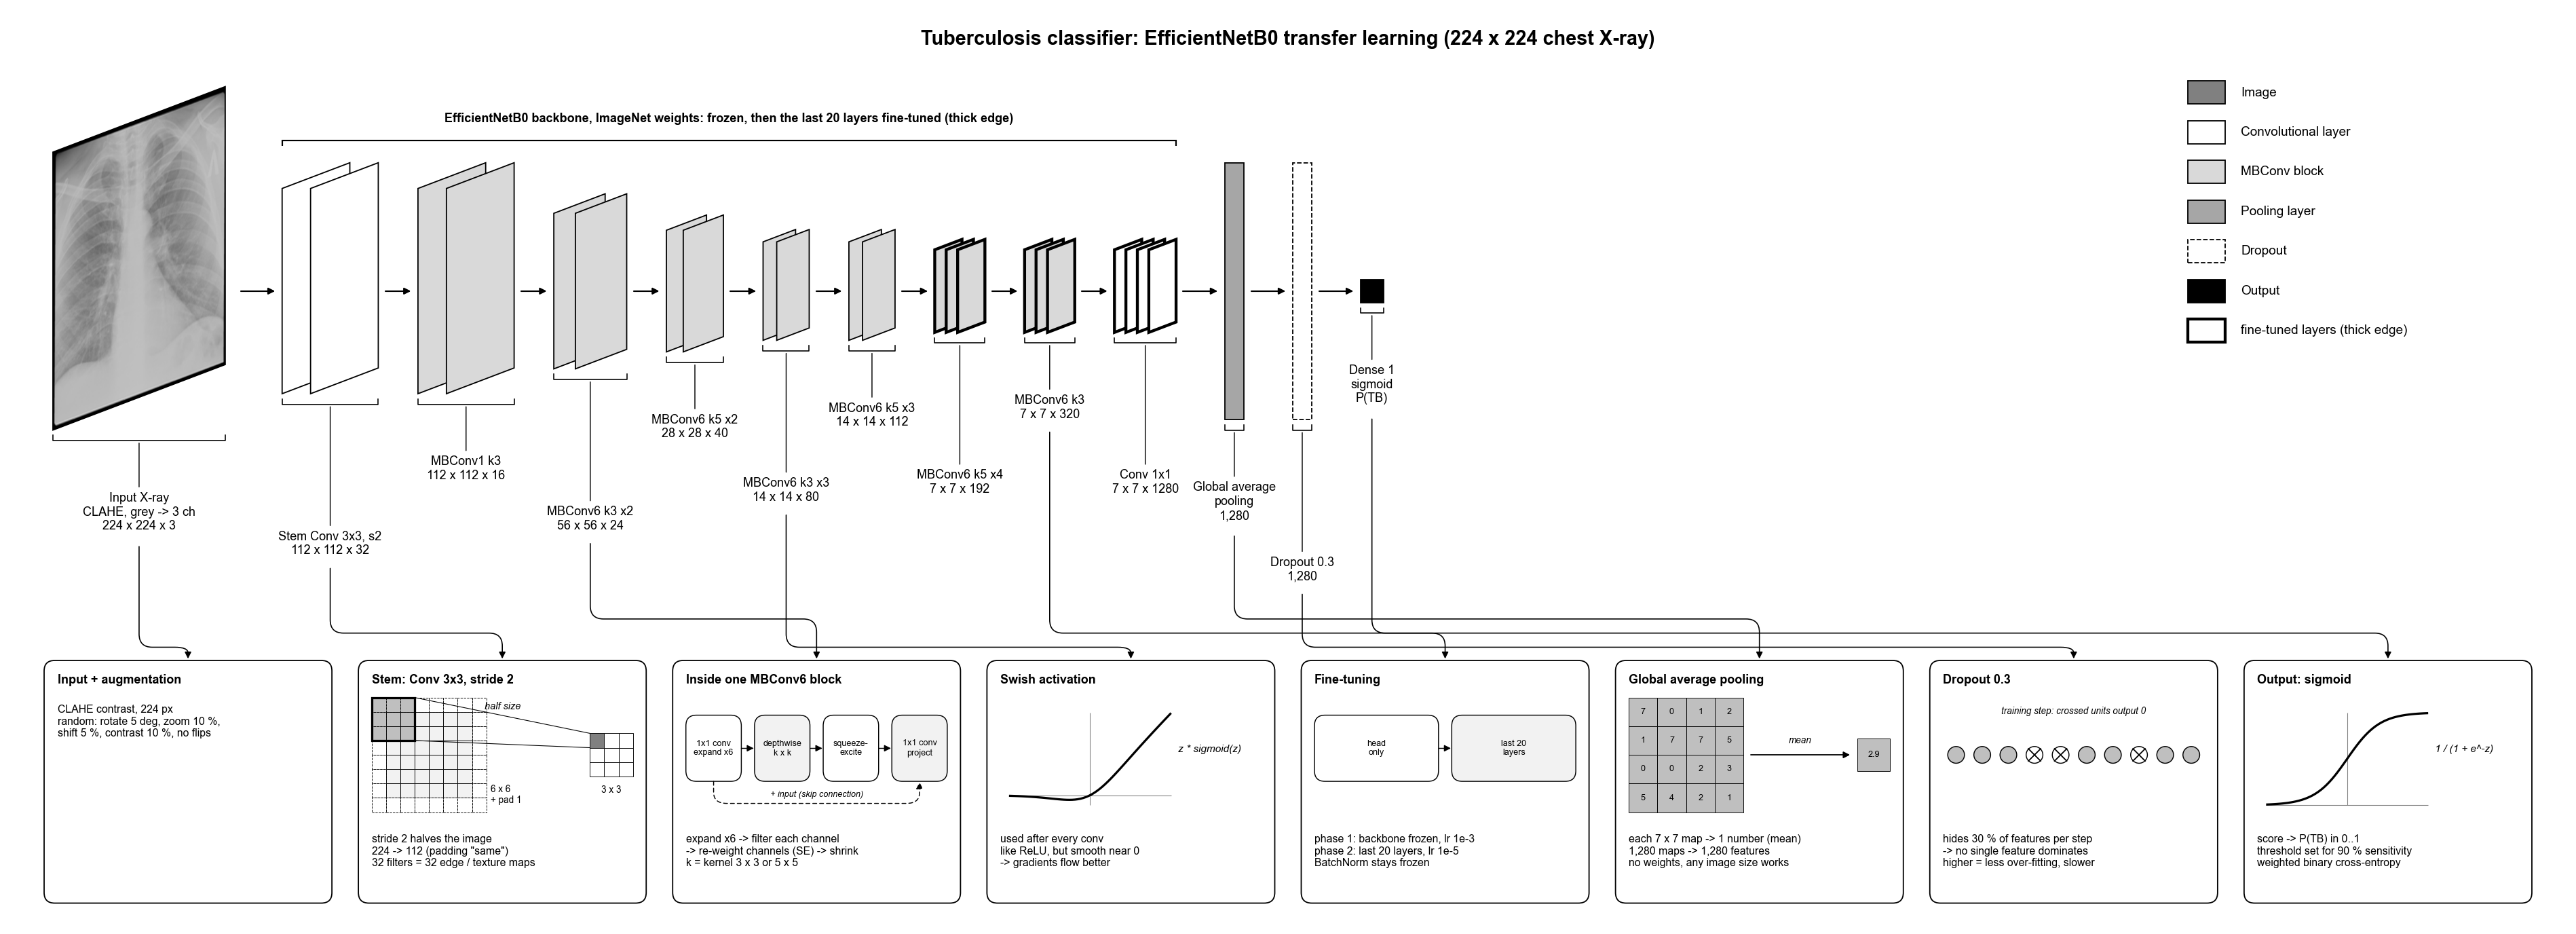

- **Stem** → one 3 × 3 convolution with stride 2: 224 × 224 → 112 × 112
- **MBConv block** → expand the channels (1 × 1 conv, × 6) → filter each channel separately (depthwise 3 × 3 or 5 × 5) → **squeeze-and-excite** re-weights the channels → project back (1 × 1) → add the input (skip connection). Cheap, because the expensive filtering is done per channel
- **Stages** → each stage halves the image and adds channels: 112 → 56 → 28 → 14 → 7 pixels, 16 → 320 channels; a final 1 × 1 conv makes 1,280 feature maps
- **Head** → global average pooling (one number per feature map) → dropout 0.3 → one sigmoid unit

$$\text{Swish}(x) = x \cdot \sigma(x)$$
- the activation inside EfficientNet: like ReLU for large $x$, but smooth around 0 and slightly negative for small $x$, which helps gradients flow
- Analogy → ReLU is a light switch, Swish is a dimmer that never snaps

In [ ]:
stage_rows = {}
fine_tuned = {l.name for l in base_model.layers[-FINE_TUNE_LAST_N:]}
for layer in base_model.layers:
    prefix = layer.name.split('_')[0]
    stage = ('stem' if prefix in ('input', 'rescaling', 'normalization', 'stem') else
             'top conv' if prefix == 'top' else f'stage {prefix[5]}')
    row = stage_rows.setdefault(stage, {'stage': stage, 'layers': 0, 'parameters': 0, 'fine-tuned layers': 0})
    row['layers'] += 1
    row['parameters'] += layer.count_params()
    row['fine-tuned layers'] += layer.name in fine_tuned
    row['output shape'] = tuple(layer.output.shape[1:])
stage_table = pd.DataFrame(stage_rows.values())
stage_table['share of parameters'] = (stage_table['parameters'] / stage_table['parameters'].sum()).round(3)

In [ ]:
display(stage_table)
show_block('Backbone', {'layers': len(base_model.layers), 'parameters': f'{base_model.count_params():,}',
                        'head parameters (GAP + dropout + dense)': f'{model.count_params() - base_model.count_params():,}'})

**What the table shows** → the network is heavy where the channels are many, not where the image is big: stage 6 (7 × 7, 192 channels) holds about half of the 4.0 M backbone parameters, while the first stages at 112 × 112 hold almost none. Fine-tuning the last 20 layers changes the end of stage 6, all of stage 7 and the final 1 × 1 conv — the most X-ray-specific, high-level features — and leaves the general edge and texture detectors untouched. The new head adds only 1,281 parameters.

**6. Knobs: what they control and what you trade**

| Knob | Here | Controls | Turn it up → | You trade |
|---|---|---|---|---|
| `IMG_SIZE` | 224 | detail the network sees | finer lesions visible | detail vs. memory and time (cost ∝ size²) |
| `ENHANCE` | `'clahe'` | local contrast of the X-ray | (a choice) clearer lung texture | visibility vs. amplified noise |
| `BATCH_SIZE` | 32 | images per update | smoother updates | stability vs. memory, fewer updates |
| `EPOCHS_HEAD` / `EPOCHS_FINE_TUNE` | 10 / 8 | training length (early stopping caps it) | more chances to improve | fit vs. over-fitting and time |
| `FINE_TUNE_LAST_N` | 20 | how much of the backbone may change | more X-ray-specific features | adaptation vs. over-fitting ~2,900 images |
| learning rate | 1e-3 head, 1e-5 fine-tune | step size of each update | faster learning | speed vs. destroying pre-trained features |
| dropout | 0.3 | share of features hidden during training | stronger regularisation | generalisation vs. under-fitting |
| `TARGET_SENSITIVITY` | 0.90 | decision threshold on validation | more TB cases caught | recall vs. more false alarms |

**Rule of thumb** → validation AUC falling while training AUC rises = over-fitting: lower `FINE_TUNE_LAST_N` or the learning rate, or add augmentation.

In [ ]:
print(f'[1/2] Train head · max {EPOCHS_HEAD} epochs')
history_head  = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_HEAD,
                          callbacks=make_callbacks(), class_weight=class_weight, verbose=2)
best_head_auc = max(history_head.history['val_auc'])
head_weights  = [(variable, variable.numpy()) for variable in model.weights]
show_block('Outputs', {'best val AUC (head)': f'{best_head_auc:.4f}'})

In [ ]:
print(f'[2/2] Fine-tune last {FINE_TUNE_LAST_N} backbone layers · max {EPOCHS_FINE_TUNE} epochs')
base_model.trainable = True
for layer in base_model.layers[:-FINE_TUNE_LAST_N]:
    layer.trainable = False
for layer in base_model.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

model.compile(optimizer=keras.optimizers.Adam(1e-5), loss='binary_crossentropy', metrics=make_metrics())
history_ft  = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_FINE_TUNE,
                        callbacks=make_callbacks(), class_weight=class_weight, verbose=2)
best_ft_auc = max(history_ft.history['val_auc'])

if best_ft_auc < best_head_auc:
    for variable, value in head_weights:
        variable.assign(value)
show_block('Outputs', {'best val AUC (head)':      f'{best_head_auc:.4f}',
                       'best val AUC (fine-tune)': f'{best_ft_auc:.4f}',
                       'weights kept':             'fine-tune' if best_ft_auc >= best_head_auc else 'head'})

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for ax, metric in zip(axes, ['loss', 'auc', 'recall']):
    train_vals = history_head.history[metric] + history_ft.history[metric]
    val_vals   = history_head.history[f'val_{metric}'] + history_ft.history[f'val_{metric}']
    epochs     = np.arange(1, len(train_vals) + 1)
    ax.plot(epochs, train_vals, label='train')
    ax.plot(epochs, val_vals, label='validation')
    ax.axvline(len(history_head.history[metric]) + 0.5, color='grey', linestyle='--', label='start fine-tuning')
    ax.set(title=metric, xlabel='epoch')
    ax.legend()
plt.tight_layout()
plt.show()

**What to look for** → validation AUC flattening while training AUC keeps rising = **overfitting** (memorising the training X-rays). Early stopping keeps the best validation epoch of each phase.

In [ ]:
"""Optional · Set SAVE_MODEL = True in the top cell to write the model file."""
if SAVE_MODEL:
    model.save(MODEL_FILE)
    print(f'Saved → {MODEL_FILE}')
else:
    print(f'Preview · would save → {MODEL_FILE} · nothing written (SAVE_MODEL = False)')

# [11/13] Evaluation

Pick the threshold on validation for screening, then score the untouched test set once → sensitivity and specificity against the WHO screening target

**Question:** How good is the model as a TB **screening** tool?

**1. Sensitivity and specificity**

$$\text{Sensitivity} = \frac{TP}{TP + FN} \qquad \text{Specificity} = \frac{TN}{TN + FP}$$
- $TP$ → TB cases flagged, $FN$ → TB cases sent home
- $TN$ → healthy people cleared, $FP$ → healthy people sent for a sputum test
- Sensitivity → share of TB cases caught; specificity → share of healthy people cleared
- Analogy → a smoke alarm: sensitivity = share of real fires it catches, specificity = share of burnt toast it ignores

**2. ROC-AUC** → the probability that a random TB X-ray scores higher than a random normal one. 0.5 = coin flip, 1.0 = perfect. It does not depend on the threshold or on the 1:5 class ratio.

**3. Threshold for screening** → a missed TB case keeps spreading the disease; a false alarm costs one sputum test. So the threshold is the **highest** one that still catches `TARGET_SENSITIVITY` = 90% of TB cases on validation, and it is reused unchanged on test. The WHO target for a TB triage test is **≥ 90% sensitivity and ≥ 70% specificity**.

**Answer:** on this test set it clears the WHO triage target with room to spare.
- ROC-AUC **0.997**, average precision 0.992
- sensitivity **93.9 %** → 93 of 99 TB cases caught, 6 missed
- specificity **99.8 %** → 1 false alarm among 498 normal X-rays (threshold 0.881, set on validation)


In [ ]:
def predict_proba(model, X):
    return model.predict(make_dataset(X, np.zeros(len(X)), training=False), verbose=0).ravel()


def threshold_for_sensitivity(y, p, target):
    fpr, tpr, thresholds = roc_curve(y, p)
    return thresholds[np.flatnonzero(tpr >= target)[0]]


def screening_metrics(y, p, threshold):
    tn, fp, fn, tp = confusion_matrix(y, (p >= threshold).astype(int), labels=[0, 1]).ravel()
    return {'ROC-AUC': roc_auc_score(y, p), 'average precision': average_precision_score(y, p),
            'sensitivity': tp / (tp + fn), 'specificity': tn / (tn + fp), 'TB missed': fn, 'false alarms': fp}


p_val     = predict_proba(model, X_val)
p_te      = predict_proba(model, X_te)
threshold = threshold_for_sensitivity(y_val, p_val, TARGET_SENSITIVITY)
y_pred_te = (p_te >= threshold).astype(int)

display(pd.DataFrame({'validation': screening_metrics(y_val, p_val, threshold),
                      'test':       screening_metrics(y_te, p_te, threshold),
                      'WHO target': {'sensitivity': 0.90, 'specificity': 0.70}}).round(4))
show_block('Outputs', {'threshold (from validation)': f'{threshold:.3f}'})

In [ ]:
display(pd.DataFrame(classification_report(y_te, y_pred_te, target_names=['normal', 'TB'], output_dict=True)).T.round(3))

In [ ]:
fig, axes = plt.subplots(1, 4, figsize=(24, 5))
for name, y_true, p in [('validation', y_val, p_val), ('test', y_te, p_te)]:
    fpr, tpr, _ = roc_curve(y_true, p)
    axes[0].plot(fpr, tpr, label=f'{name} (AUC = {roc_auc_score(y_true, p):.3f})')
    precision, recall, _ = precision_recall_curve(y_true, p)
    axes[1].plot(recall, precision, label=f'{name} (AP = {average_precision_score(y_true, p):.3f})')
axes[0].plot([0, 1], [0, 1], color='grey', linestyle='--', label='random')
axes[0].add_patch(plt.Rectangle((0, 0.9), 0.3, 0.1, color='green', alpha=0.15, label='WHO target zone'))
axes[0].set(xlabel='1 − specificity', ylabel='Sensitivity', title='ROC curve')
axes[1].axhline(y_te.mean(), color='grey', linestyle='--', label='random (test)')
axes[1].set(xlabel='Recall (sensitivity)', ylabel='Precision', title='Precision-recall curve')
axes[0].legend()
axes[1].legend()

for cls in [0, 1]:
    axes[2].hist(p_te[y_te == cls], bins=25, range=(0, 1), alpha=0.6, color=PALETTE[cls], label=CLASS_NAMES[cls])
axes[2].axvline(threshold, color='blue', linestyle='--', label=f'threshold {threshold:.2f}')
axes[2].set(xlabel='Predicted P(TB)', ylabel='Test images', title='Predicted probabilities (test)', yscale='log')
axes[2].legend()

ConfusionMatrixDisplay(confusion_matrix(y_te, y_pred_te), display_labels=['normal', 'TB']).plot(ax=axes[3], cmap='Greys', colorbar=False)
axes[3].set_title('Test confusion matrix')
axes[3].grid(False)
plt.tight_layout()
plt.show()

# [12/13] Where does the CNN look?

Hide the lungs, show only the lungs, then explain single X-rays with LIME → a model that still finds TB with the lungs hidden has learned a shortcut

**Question:** If we black out the lungs, can the model still tell TB from normal?

The test X-rays are scored three times with the **same** trained model:
- **full image** → as trained
- **lungs only** → everything outside the lung mask set to black
- **lungs hidden** → the lungs set to black, the rest kept

If the score with the lungs hidden stays far above 0.5, the model finds TB **outside** the lungs: in text markers, borders, body shape or exposure, the fingerprints of the hospital each class came from. Both masked versions look unusual to the model, so some drop is expected either way; the gap between them is the clue.

**Answer:** yes, and that is the key finding.
- lungs hidden → ROC-AUC still **0.981**: most of the separation is possible from outside the lungs (borders, markers, the source fingerprints of [2/13]-[6/13])
- lungs only → 0.691: a black background is unlike anything the model trained on
- → the 0.997 is real on this dataset, but part of it is "which hospital"; a new hospital's X-rays would likely score lower (next step: source-held-out test)


In [ ]:
m_te      = masks[test_idx]
occlusion = {'full image':   X_te,
             'lungs only':   np.where(m_te, X_te, 0).astype(np.uint8),
             'lungs hidden': np.where(m_te, 0, X_te).astype(np.uint8)}
occ_proba = {name: predict_proba(model, X) for name, X in occlusion.items()}
display(pd.DataFrame({name: {'ROC-AUC':                  roc_auc_score(y_te, p),
                             'mean P(TB) on TB images':  p[y_te == 1].mean(),
                             'mean P(TB) on normal':     p[y_te == 0].mean(),
                             'TB still flagged':         ((p >= threshold) & (y_te == 1)).sum() / (y_te == 1).sum()}
                      for name, p in occ_proba.items()}).T.round(3))

In [ ]:
ids = [*show_rng.choice(np.flatnonzero(y_te == 0), 2, replace=False), *show_rng.choice(np.flatnonzero(y_te == 1), 2, replace=False)]
fig, axes = plt.subplots(len(ids), 3, figsize=(12, 4.25 * len(ids)))
for row, i in enumerate(ids):
    for col, (name, X) in enumerate(occlusion.items()):
        axes[row, col].imshow(X[i], cmap='gray', vmin=0, vmax=255)
        axes[row, col].set_title(f'{name}\ntrue {CLASS_NAMES[y_te[i]]} · P(TB) = {occ_proba[name][i]:.2f}', color=PALETTE[y_te[i]])
        axes[row, col].axis('off')
plt.suptitle('The same model on full, lungs-only and lungs-hidden X-rays', fontweight='bold')
plt.tight_layout()
plt.show()

**Question:** For single X-rays, which regions push the model towards TB?

LIME explains one prediction at a time:

$$\xi(x) = \underset{g}{\arg\min}\; \mathcal{L}(f, g, \pi_x) + \Omega(g)$$
- $x$ → the X-ray being explained, cut into **superpixels** (patches of similar brightness)
- $f$ → our CNN, the black box
- $g$ → a simple linear model: one weight per superpixel
- $\pi_x$ → closeness weight: perturbed images that still look like $x$ count more
- $\mathcal{L}$ → how badly $g$ imitates $f$ on those perturbed images
- $\Omega(g)$ → complexity penalty: keep only the top few superpixels
- Analogy → finding which ingredient makes a soup salty by cooking it many times, each time leaving out random ingredients, and tasting
- Colours → green pushes towards TB, red towards normal; yellow = superpixel borders; cyan line = lung mask

**Answer:** mixed, and consistent with the lungs-hidden test.
- true positive → green patches in the left lung, but also a black border strip
- false negative and false positive → the strongest superpixels sit on the abdomen, the edges and the collarbones
- → use the map as a check on each decision, not as proof that the model reads TB lesions


In [ ]:
def classifier_fn(images):
    p = model.predict(np.asarray(images, dtype=np.float32), batch_size=64, verbose=0).ravel()
    return np.stack([1 - p, p], axis=1)


explainer = lime_image.LimeImageExplainer(random_state=SEED)
segmenter = SegmentationAlgorithm('slic', n_segments=60, compactness=10, start_label=0, random_seed=SEED)

In [ ]:
case_masks = {
    'true positive':  (y_te == 1) & (y_pred_te == 1),
    'false negative': (y_te == 1) & (y_pred_te == 0),
    'false positive': (y_te == 0) & (y_pred_te == 1),
    'true negative':  (y_te == 0) & (y_pred_te == 0),
}
rng    = np.random.default_rng(SEED)
chosen = pd.DataFrame([{'case': name, 'test index': int(rng.choice(np.flatnonzero(mask)))}
                       for name, mask in case_masks.items() if mask.any()])
chosen['file']     = files_df.loc[test_idx[chosen['test index']], 'file'].to_numpy()
chosen['true']     = pd.Series(y_te[chosen['test index']]).map(CLASS_NAMES)
chosen['P(TB)']    = p_te[chosen['test index']].round(3)

empty_cases = [name for name, mask in case_masks.items() if not mask.any()]
if empty_cases:
    print('(!) No test images for: ' + ', '.join(empty_cases))
display(chosen)

In [ ]:
fig, axes = plt.subplots(len(chosen), 3, figsize=(13, 4.4 * len(chosen)), squeeze=False)
for row, (_, case) in enumerate(chosen.iterrows()):
    print(f"[{row + 1}/{len(chosen)}] LIME · {case['case']} · {case['file']}")
    if case['case'] == 'false negative':
        print('    (!) a TB case the model sent home')
    i           = case['test index']
    rgb         = np.repeat(X_te[i][..., None], 3, axis=-1)
    explanation = explainer.explain_instance(rgb, classifier_fn, labels=(1,), hide_color=0, segmentation_fn=segmenter,
                                             num_samples=LIME_SAMPLES, batch_size=64, random_seed=SEED)
    img_pos, mask_pos   = explanation.get_image_and_mask(1, positive_only=True, num_features=5, hide_rest=False)
    img_both, mask_both = explanation.get_image_and_mask(1, positive_only=False, num_features=10, hide_rest=False)

    axes[row, 0].imshow(X_te[i], cmap='gray')
    axes[row, 0].set_title(f"{case['case']}\ntrue = {case['true']}, P(TB) = {case['P(TB)']:.2f}")
    axes[row, 1].imshow(mark_boundaries(img_pos / 255.0, mask_pos))
    axes[row, 1].set_title('Top 5 superpixels supporting "TB"')
    axes[row, 2].imshow(mark_boundaries(img_both / 255.0, mask_both))
    axes[row, 2].set_title('Top 10: green = towards TB, red = towards normal')
    for ax in axes[row]:
        ax.contour(m_te[i], colors='cyan', linewidths=1.5)
        ax.axis('off')

plt.suptitle('LIME explanations on the test set', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

# [13/13] Gradio app

Wrap the trained model in a small screening app → upload an X-ray, get P(TB), a decision at the screening threshold and a LIME map

- **Same preprocessing** → grayscale, `IMG_SIZE`, `ENHANCE`, exactly as in training
- **Decision** → P(TB) ≥ the validation threshold from [11/13] → "refer for a sputum test"
- **Run it** → set `LAUNCH_APP = True` (Kaggle prints a temporary public link); the standalone `app.py` in the repository does the same locally

In [ ]:
def screen(image):
    gray = image if image.ndim == 2 else cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)
    x    = ENHANCERS[ENHANCE](cv2.resize(gray, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_AREA))
    rgb  = np.repeat(x[..., None], 3, axis=-1)
    p    = float(classifier_fn(rgb[None])[0, 1])
    text = (f'### {"Possible TB → refer for a sputum test" if p >= threshold else "No TB pattern found → routine care"}\n'
            f'P(TB) = **{p:.3f}** · threshold {threshold:.3f}')
    explanation = explainer.explain_instance(rgb, classifier_fn, labels=(1,), hide_color=0, segmentation_fn=segmenter,
                                             num_samples=LIME_SAMPLES, batch_size=64, random_seed=SEED)
    img, mask = explanation.get_image_and_mask(1, positive_only=False, num_features=10, hide_rest=False)
    fig, ax = plt.subplots(figsize=(5, 5))
    ax.imshow(mark_boundaries(img / 255.0, mask))
    ax.contour(lung_mask(x), colors='cyan', linewidths=1.2)
    ax.set_title('LIME: green → TB, red → normal')
    ax.axis('off')
    return {'Tuberculosis': p, 'Normal': 1 - p}, text, fig


if SAVE_MODEL:
    with open(SETTINGS_FILE, 'w') as f:
        json.dump({'img_size': IMG_SIZE, 'enhance': ENHANCE, 'threshold': float(threshold)}, f)
    print(f'Saved → {SETTINGS_FILE}')

if LAUNCH_APP:
    import gradio as gr
    with gr.Blocks(title='Tuberculosis X-ray screening') as demo:
        gr.Markdown('# Tuberculosis Chest X-ray Screening')
        with gr.Row():
            inp = gr.Image(type='numpy', label='Chest X-ray')
            with gr.Column():
                prob, text, plot = gr.Label(num_top_classes=2), gr.Markdown(), gr.Plot()
        gr.Button('Screen', variant='primary').click(screen, inputs=inp, outputs=[prob, text, plot])
        gr.Examples([[p] for p in files_df.loc[test_idx[:6], 'path']], inputs=inp)
    demo.launch(share=True)
else:
    print('Preview · app not started (LAUNCH_APP = False)')

**Next steps**
- **Source-held-out test** → train on some collections and test on another; the only honest answer to "does it work in a new hospital?"
- **Learned lung segmentation** → a U-Net trained on the Montgomery / Shenzhen lung masks, then train the classifier on lungs only
- **Grad-CAM** → a second explanation method that reads the CNN's own feature maps, to cross-check LIME
- **More TB images** → the 2,800 extra TB X-rays from the NIAID portal (data agreement required) would ease the 1:5 imbalance
- **Calibration** → check that P(TB) = 0.8 really means 8 in 10 such X-rays show TB